Unemployment Trends in India: A Data-Driven Analysis

Project Overview

This project investigates unemployment trends in India through exploratory data analysis and statistical visualization. The analysis focuses on changes over time, differences across regions, and patterns observed around the COVID-19 pandemic.

Objectives
Assess data quality and prepare the dataset for analysis.
Examine unemployment trends over time.
Compare observations before and after the onset of the COVID-19 pandemic.
Investigate regional variation and monthly patterns.
Develop evidence-based observations relevant to employment policy.
Tools and Technologies

Python · Pandas · NumPy · Matplotlib · Seaborn · Jupyter Notebook

Analytical Approach

Data validation → Data cleaning → Exploratory analysis → Visualization → Interpretation and recommendations

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Unemployment in India.csv")

In [4]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [6]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows without an unemployment rate
df = df.dropna(subset=[" Estimated Unemployment Rate (%)"])

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("\nData cleaned successfully!")
print("Rows and columns:", df.shape)

df.head()

Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Data cleaned successfully!
Rows and columns: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


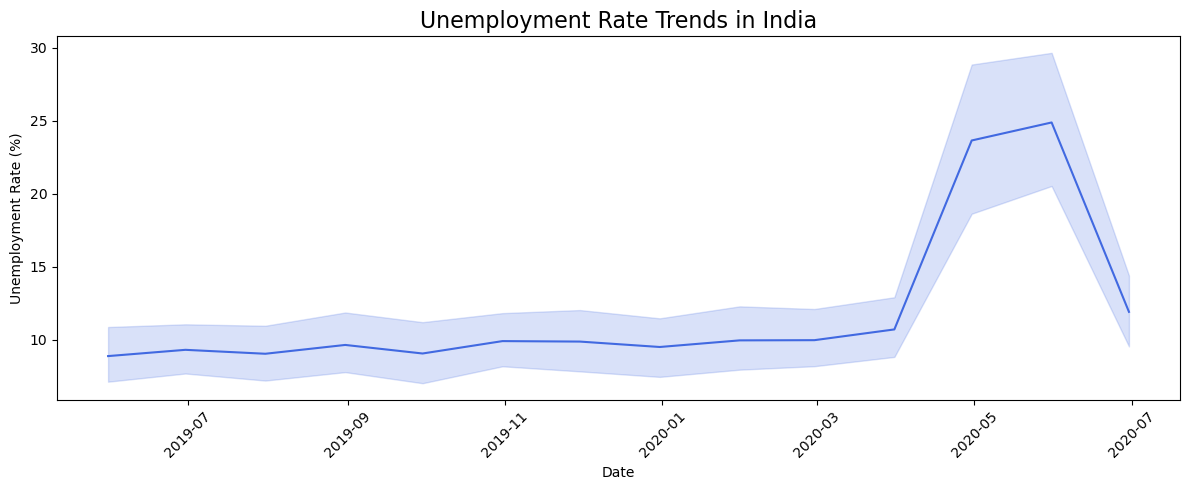

In [7]:
# Convert the Date column into date format
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Sort data by date
df = df.sort_values("Date")

# Create the graph
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    color="royalblue"
)

plt.title("Unemployment Rate Trends in India", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()





Average unemployment before COVID-19: 9.51 %
Average unemployment from March 2020 onward: 17.77 %


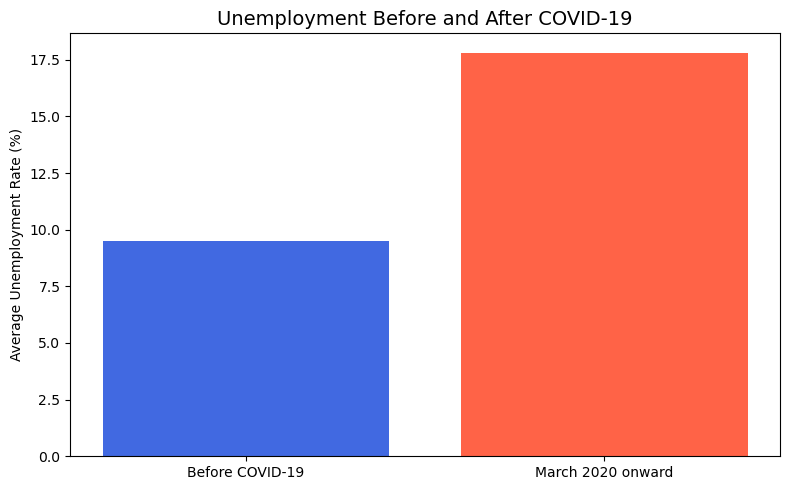

In [8]:
# Divide the data into two periods
before_covid = df[df["Date"] < "2020-03-01"]

after_covid = df[df["Date"] >= "2020-03-01"]

# Calculate average unemployment rates
before_rate = before_covid["Estimated Unemployment Rate (%)"].mean()
after_rate = after_covid["Estimated Unemployment Rate (%)"].mean()

print("Average unemployment before COVID-19:", round(before_rate, 2), "%")
print("Average unemployment from March 2020 onward:", round(after_rate, 2), "%")

# Create a bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    ["Before COVID-19", "March 2020 onward"],
    [before_rate, after_rate],
    color=["royalblue", "tomato"]
)

plt.title("Unemployment Before and After COVID-19", fontsize=14)
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

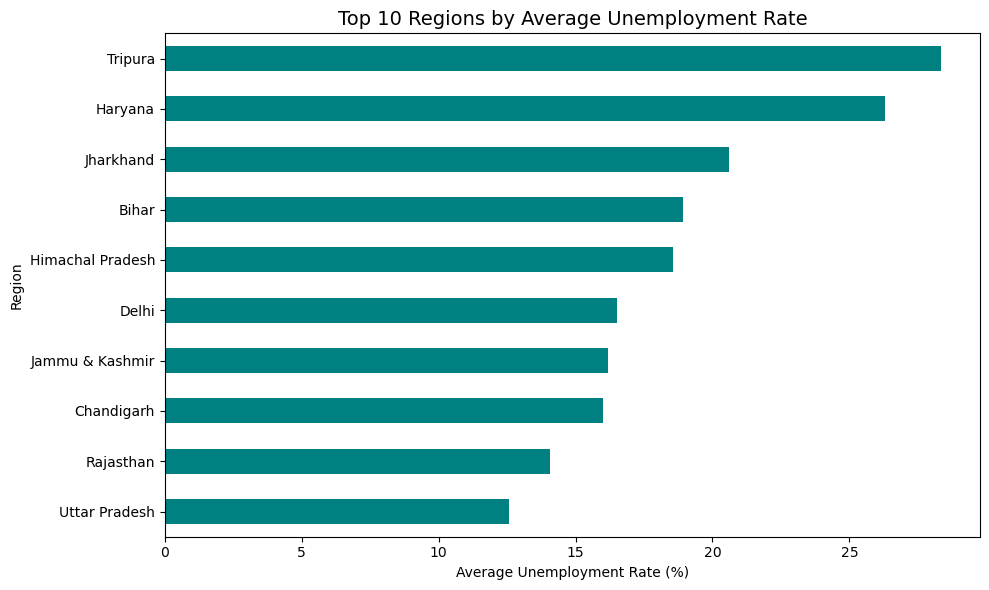

In [9]:
# Calculate average unemployment rate for each region
region_rates = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False)

# Select the 10 regions with the highest averages
top_regions = region_rates.head(10).sort_values()

# Create the graph
plt.figure(figsize=(10, 6))

top_regions.plot(kind="barh", color="teal")

plt.title("Top 10 Regions by Average Unemployment Rate", fontsize=14)
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

Conclusion

In this project, I analyzed unemployment trends in India using Python.

I cleaned the dataset and created visualizations to understand changes in unemployment rates over time, compare the periods before and after March 2020, and identify regional differences.

Key Observations
The time-series graph shows how unemployment rates changed during the recorded period.
The COVID-19 comparison highlights differences in average recorded unemployment rates before and after March 2020.
The regional analysis identifies regions with higher average unemployment rates in the dataset.
Policy Implications

The findings highlight the importance of monitoring employment trends, supporting workers during economic disruptions, and creating policies that improve access to employment opportunities.

Learning Outcomes

Through this project, I gained practical experience in Python, Pandas, data cleaning, data visualization, and exploratory data analysis.

Note: The analysis describes patterns in the available data. The before-and-after comparison alone does not establish that COVID-19 caused the observed changes.